<a href="https://colab.research.google.com/github/isabelcordova-hash/Analitica-Empresarial-Integrada/blob/main/LAB_D12_AEI_C%C3%93RDOVA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Laboratorio dirigido 12 (caso 2) — Analítica de procesos internos**

**Estudiante:** Isabel Córdova Agurto

**Caso:** monitoreo de la demanda de viajes de una flota de taxis y priorización de alertas operativas de despacho.
**Datos reales:** Numenta Anomaly Benchmark (NAB), serie `nyc_taxi`: número de pasajeros de taxis de Nueva York agregado cada 30 minutos, del 1 de julio de 2014 al 31 de enero de 2015 (datos de la NYC Taxi and Limousine Commission incluidos en NAB).
**Pregunta:** ¿qué lecturas y qué días de demanda merecen revisión primero por parte del equipo de despacho, sin afirmar que hubo un evento operativo a partir de una simple rareza estadística?

> Referencia: Lavin, A. y Ahmad, S. (2015). *Evaluating Real-Time Anomaly Detection Algorithms — The Numenta Anomaly Benchmark.* 14th IEEE International Conference on Machine Learning and Applications.



## Objetivos y teoría
La detección de anomalías identifica observaciones poco habituales según un conjunto de variables. Isolation Forest produce una puntuación de rareza; el umbral se calibra exclusivamente con la línea base. La carta p monitorea la proporción diaria de lecturas en alerta con límites que dependen del número de lecturas de cada día.

En este caso la demanda tiene un **ciclo semanal muy marcado** (la madrugada es baja, la tarde es alta y el domingo no se parece al viernes). Una lectura baja a las 4:00 a. m. es normal; la misma lectura a las 6:00 p. m. no lo es. Por eso se construye un **perfil esperado por día de la semana y media hora**, calculado **solo con la línea base**, y se mide cuánto se aleja cada lectura de lo esperado (el residuo). Una alerta es un motivo para investigar, no una prueba de que ocurrió un evento operativo.

Los autores de NAB señalan **ventanas de anomalía** en la serie. Se usan solo como referencia para contrastar las alertas **después** de calibrar el modelo: son ventanas aproximadas y la fuente no explica la causa de cada una.

## Paso 1. Cargar datos abiertos y conservar trazabilidad
Fuente de los datos: https://github.com/numenta/NAB/blob/master/data/realKnownCause/nyc_taxi.csv . Etiquetas: https://github.com/numenta/NAB/blob/master/labels/combined_windows.json . Licencia del repositorio: MIT (Numenta, 2014-2024).

In [1]:
!pip -q install scikit-learn
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
BASE_URL = "https://raw.githubusercontent.com/numenta/NAB/master/"
URL_DATOS = BASE_URL + "data/realKnownCause/nyc_taxi.csv"
URL_ETIQ = BASE_URL + "labels/combined_windows.json"
raw = pd.read_csv(URL_DATOS, parse_dates=["timestamp"])
print("Filas originales:", len(raw), "Columnas:", list(raw.columns))
print("Desde", raw.timestamp.min(), "hasta", raw.timestamp.max())
print(raw.head())

Filas originales: 10320 Columnas: ['timestamp', 'value']
Desde 2014-07-01 00:00:00 hasta 2015-01-31 23:30:00
            timestamp  value
0 2014-07-01 00:00:00  10844
1 2014-07-01 00:30:00   8127
2 2014-07-01 01:00:00   6210
3 2014-07-01 01:30:00   4656
4 2014-07-01 02:00:00   3820


## Paso 2. Reglas de calidad y variables derivadas
Se retiran las marcas de tiempo repetidas (se conserva la primera), se ordena la serie y se verifica que cada día tenga sus 48 lecturas de 30 minutos. Son reglas analíticas declaradas, no verdades de la fuente. Las variables derivadas resumen las últimas 3 horas (6 lecturas): media, desviación y cambio respecto de hace 3 horas. Las 6 primeras lecturas no tienen historia suficiente y se descartan.

In [2]:
# Marcas de tiempo repetidas: se conserva la primera lectura de cada instante
repetidas = raw.timestamp.duplicated(keep="first")
df = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")
# Se comprueba que todas las lecturas están separadas por 30 minutos
fuera_de_paso = int((df.index.to_series().diff().dropna() != pd.Timedelta(minutes=30)).sum())
# Días completos: cada día debe tener 48 lecturas
por_dia = df.groupby(df.index.normalize()).size()
dias_incompletos = int((por_dia != 48).sum())
print("Marcas repetidas:", int(repetidas.sum()), "· lecturas útiles:", len(raw) - int(repetidas.sum()))
print("Lecturas fuera del paso de 30 min:", fuera_de_paso, "· días con lecturas incompletas:", dias_incompletos, "de", len(por_dia))
print(df.value.describe().round(1))
print("Lecturas por debajo de 100 pasajeros:", int((df.value < 100).sum()))
# Variables derivadas de las últimas 3 horas; las 6 primeras lecturas no tienen historia suficiente
feat = pd.DataFrame({"valor": df.value,
                     "media_3h": df.value.rolling(6).mean(),
                     "desv_3h": df.value.rolling(6).std(),
                     "cambio_3h": df.value.diff(6)}).dropna()
print("Lecturas con variables completas:", len(feat))

Marcas repetidas: 0 · lecturas útiles: 10320
Lecturas fuera del paso de 30 min: 0 · días con lecturas incompletas: 0 de 215
count    10320.0
mean     15137.6
std       6939.5
min          8.0
25%      10262.0
50%      16778.0
75%      19838.8
max      39197.0
Name: value, dtype: float64
Lecturas por debajo de 100 pasajeros: 12
Lecturas con variables completas: 10314


## Paso 3. Separar línea base y periodo de seguimiento, y construir el perfil esperado
Línea base: 1 de julio al 15 de octubre de 2014. Seguimiento: 16 de octubre de 2014 al 31 de enero de 2015. La separación se fija antes de examinar las alertas. El **perfil esperado** (mediana de la línea base para cada combinación de día de la semana y media hora) se calcula solo con la línea base y se aplica a todo el periodo, de modo que no hay fuga de información del seguimiento. Las ventanas de NAB se cargan solo para contrastar los resultados.

In [3]:
CORTE = pd.Timestamp("2014-10-16")
base = feat.index < CORTE

# Ranura semanal: 0 a 335 (7 días x 48 medias horas)
def ranura(ix):
    return ix.dayofweek * 48 + ix.hour * 2 + ix.minute // 30

feat["ranura"] = ranura(feat.index)
# El perfil esperado se calcula SOLO con la línea base
perfil = feat.loc[base].groupby("ranura").valor.median()
feat["esperado"] = feat.ranura.map(perfil)
feat["resid"] = feat.valor - feat.esperado               # distancia a lo esperado
feat["resid_3h"] = feat.resid.rolling(6).mean()          # residuo promedio de las últimas 3 horas
feat = feat.dropna()
base = feat.index < CORTE
VARIABLES = ["valor", "resid", "resid_3h", "desv_3h", "cambio_3h"]

# Ventanas de anomalía señaladas por los autores de NAB (solo referencia para contrastar)
etiquetas = json.load(urllib.request.urlopen(URL_ETIQ))["realKnownCause/nyc_taxi.csv"]
ventanas = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in etiquetas]
en_ventana = pd.Series(False, index=feat.index)
for a, b in ventanas:
    en_ventana.loc[a:b] = True
print("Línea base:", int(base.sum()), "lecturas · Seguimiento:", int((~base).sum()), "lecturas")
print("Ventanas de referencia:")
for a, b in ventanas:
    print("  ", str(a)[:16], "->", str(b)[:16])
print("Lecturas de la línea base dentro de una ventana:", int(en_ventana[base].sum()))
assert base.sum() > 5000 and (~base).sum() > 5000
assert en_ventana[base].sum() == 0, "La línea base no debe contener ventanas de referencia"

Línea base: 5125 lecturas · Seguimiento: 5184 lecturas
Ventanas de referencia:
   2014-10-30 15:30 -> 2014-11-03 22:30
   2014-11-25 12:00 -> 2014-11-29 19:00
   2014-12-23 11:30 -> 2014-12-27 18:30
   2014-12-29 21:30 -> 2015-01-03 04:30
   2015-01-24 20:30 -> 2015-01-29 03:30
Lecturas de la línea base dentro de una ventana: 0


## Paso 4. Detectar lecturas inusuales
El bosque se ajusta solo con la línea base. Una puntuación mayor significa una lectura más atípica. El percentil 99 de la puntuación base fija la alerta principal. El modelo aprende patrones estadísticos; no conoce la causa de una lectura (feriado, clima, falla de registro o cambio real de demanda).

Umbral: 0.5918
Alertas en la línea base: 52
Alertas en el seguimiento: 347


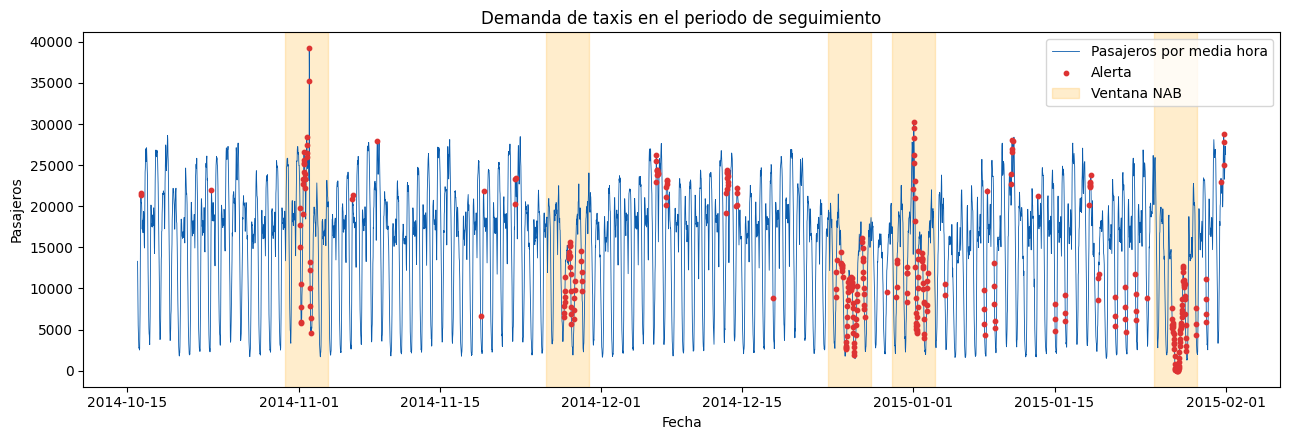

In [4]:
modelo = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
# El modelo aprende lo normal solo con la línea base
modelo.fit(feat.loc[base, VARIABLES])
# Puntuación de rareza: mayor valor significa lectura más atípica
feat["score"] = -modelo.score_samples(feat[VARIABLES])
# Umbral: percentil 99 de las puntuaciones de la línea base
umbral = feat.loc[base, "score"].quantile(0.99)
feat["alerta"] = feat.score >= umbral
print("Umbral:", round(umbral, 4))
print("Alertas en la línea base:", int(feat.loc[base, "alerta"].sum()))
print("Alertas en el seguimiento:", int(feat.loc[~base, "alerta"].sum()))

# Vista general: demanda del seguimiento, alertas y ventanas de referencia
seg = feat.loc[~base]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(seg.index, seg.valor, color="#0B5CAD", lw=0.6, label="Pasajeros por media hora")
ax.scatter(seg.index[seg.alerta], seg.valor[seg.alerta], color="#D33", s=10, label="Alerta", zorder=3)
for i, (a, b) in enumerate(ventanas):
    ax.axvspan(a, b, color="orange", alpha=0.2, label="Ventana NAB" if i == 0 else None)
ax.set(title="Demanda de taxis en el periodo de seguimiento", ylabel="Pasajeros", xlabel="Fecha")
ax.legend(); plt.tight_layout(); plt.show()

## Paso 5. Carta p con límites diarios
La proporción base p̄ es el total de alertas base dividido por el total de lecturas base. Cada límite superior usa el número n de lecturas del día (48). Se muestran todos los días, pero la evaluación de señales fuera de control se hace sobre el seguimiento. Las lecturas contiguas están correlacionadas, de modo que el supuesto binomial es una aproximación.

In [5]:
diario = feat.groupby(feat.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
pbar = feat.loc[base, "alerta"].mean()
diario["tasa"] = diario.alertas / diario.lecturas
diario["lsc"] = pbar + 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas)
diario["lic"] = np.maximum(0, pbar - 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))
diario["fuera"] = (diario.tasa > diario.lsc) | (diario.tasa < diario.lic)
seguimiento = diario.loc[CORTE:].copy()
print("p̄ =", round(pbar, 5))
print(seguimiento[["lecturas", "alertas", "tasa", "lsc", "fuera"]].query("fuera").to_string())
print("Días fuera de control en el seguimiento:", [str(d)[:10] for d in seguimiento.index[seguimiento.fuera]])
print("Días de la línea base fuera de límites:", int(diario.loc[:CORTE - pd.Timedelta(days=1), "fuera"].sum()), "de", int((diario.index < CORTE).sum()))

p̄ = 0.01015
            lecturas  alertas      tasa       lsc  fuera
timestamp                                               
2014-11-01        48       23  0.479167  0.053541   True
2014-11-02        48        8  0.166667  0.053541   True
2014-11-22        48        3  0.062500  0.053541   True
2014-11-27        48       18  0.375000  0.053541   True
2014-11-28        48        9  0.187500  0.053541   True
2014-11-29        48        5  0.104167  0.053541   True
2014-12-06        48        9  0.187500  0.053541   True
2014-12-07        48        6  0.125000  0.053541   True
2014-12-13        48       10  0.208333  0.053541   True
2014-12-14        48        4  0.083333  0.053541   True
2014-12-24        48       13  0.270833  0.053541   True
2014-12-25        48       26  0.541667  0.053541   True
2014-12-26        48       18  0.375000  0.053541   True
2014-12-27        48        8  0.166667  0.053541   True
2014-12-30        48        4  0.083333  0.053541   True
2014-12-31        

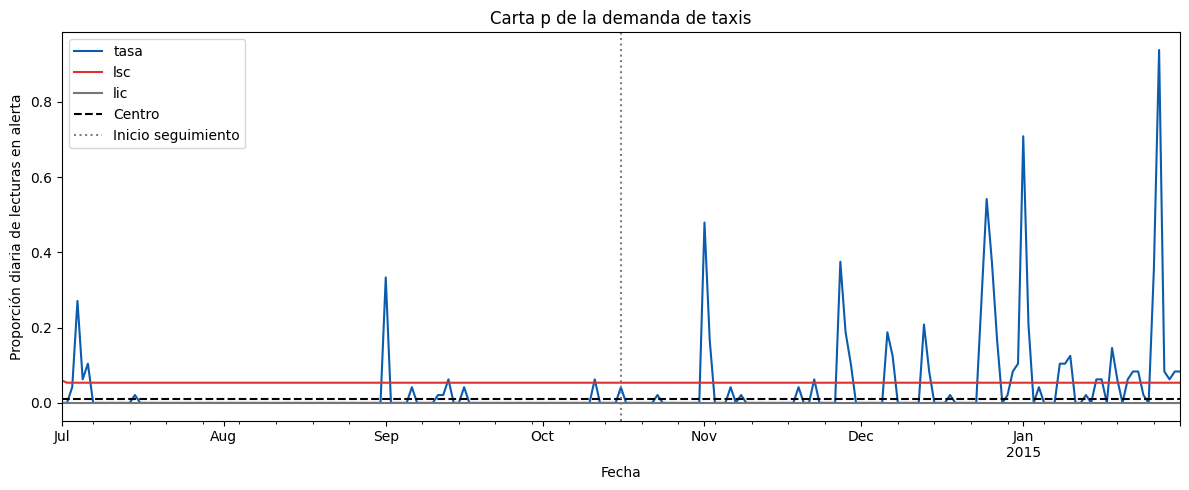

In [6]:
ax = diario[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])
ax.axhline(pbar, color="black", ls="--", label="Centro")
ax.axvline(CORTE, color="gray", ls=":", label="Inicio seguimiento")
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p de la demanda de taxis")
ax.legend(); plt.tight_layout(); plt.show()

## Paso 6. Convertir alertas en una cola de revisión
Un **episodio** agrupa las alertas separadas por 60 minutos o menos (a lo sumo una lectura faltante entre dos alertas): es la unidad que el equipo revisa. La capacidad de **1 episodio por día** es un **supuesto académico**. La prioridad es la puntuación máxima del episodio. Se calcula la cola y se contrasta con las ventanas de NAB: un episodio coincide con una ventana si se superponen en el tiempo.

In [7]:
CAPACIDAD_DIA = 1
GAP = pd.Timedelta(minutes=60)

def construir_episodios(alerta, score, desde):
    # Agrupa alertas separadas por GAP o menos y los resume por episodio
    a = pd.DataFrame({"score": score[alerta]}).reset_index()
    a["episodio"] = (a.timestamp.diff() > GAP).cumsum()
    e = a.groupby("episodio").agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                  lecturas=("score", "size"), score_max=("score", "max"))
    e["dia"] = e.inicio.dt.normalize()
    e["en_ventana"] = [any((i <= b) and (f >= a_) for a_, b in ventanas) for i, f in zip(e.inicio, e.fin)]
    return e[e.inicio >= desde].copy()

ep = construir_episodios(feat.alerta, feat.score, CORTE)
# Prioridad dentro de cada día por puntuación máxima; se revisan los primeros hasta completar la capacidad
ep["orden_dia"] = ep.groupby("dia").score_max.rank(method="first", ascending=False)
ep["revisable"] = ep.orden_dia <= CAPACIDAD_DIA
ep["duracion"] = ep.fin - ep.inicio
print("Episodios en el seguimiento:", len(ep), "· revisables:", int(ep.revisable.sum()), "· en cola:", int((~ep.revisable).sum()))
print("Episodios que coinciden con una ventana:", int(ep.en_ventana.sum()))
print("Lecturas en alerta dentro de ventanas:", int((feat.loc[~base, "alerta"] & en_ventana[~base]).sum()), "de", int(feat.loc[~base, "alerta"].sum()))
display(ep.sort_values("score_max", ascending=False).head(10)[["inicio", "fin", "duracion", "lecturas", "score_max", "en_ventana"]].round({"score_max": 3}))

Episodios en el seguimiento: 55 · revisables: 42 · en cola: 13
Episodios que coinciden con una ventana: 23
Lecturas en alerta dentro de ventanas: 250 de 347


,inicio,fin,duracion,lecturas,score_max,en_ventana
episodio,,,,,,
21,2014-11-02 01:00:00,2014-11-02 04:30:00,0 days 03:30:00,8,0.759,True
47,2015-01-01 00:00:00,2015-01-01 12:00:00,0 days 12:00:00,25,0.754,True
66,2015-01-27 05:00:00,2015-01-28 01:30:00,0 days 20:30:00,41,0.742,True
65,2015-01-26 15:30:00,2015-01-27 03:30:00,0 days 12:00:00,25,0.732,True
39,2014-12-25 06:30:00,2014-12-25 12:30:00,0 days 06:00:00,13,0.723,True
41,2014-12-25 18:00:00,2014-12-26 03:00:00,0 days 09:00:00,19,0.710,True
55,2015-01-10 18:00:00,2015-01-10 20:00:00,0 days 02:00:00,4,0.704,False
32,2014-12-06 11:00:00,2014-12-06 15:00:00,0 days 04:00:00,9,0.703,False
19,2014-11-01 10:00:00,2014-11-01 15:30:00,0 days 05:30:00,12,0.692,True


## Paso 7. Sensibilidad del umbral
Compare los percentiles base 98, 99 y 99,5. Para cada uno reporte alertas de seguimiento, episodios, episodios que coinciden con una ventana, días fuera de control y cola con la capacidad de 1 episodio por día. El umbral se calcula siempre en la línea base.

In [8]:
filas = []
for q in [0.98, 0.99, 0.995]:
    corte_q = feat.loc[base, "score"].quantile(q)
    a = feat.score >= corte_q
    pq = a[base].mean()
    n_dia = a.groupby(a.index.normalize()).size()
    k_dia = a.groupby(a.index.normalize()).sum()
    lsc_q = pq + 3 * np.sqrt(pq * (1 - pq) / n_dia)
    fuera_q = int(((k_dia / n_dia > lsc_q) & (n_dia.index >= CORTE)).sum())
    e = construir_episodios(a, feat.score, CORTE)
    cola = int((e.groupby("dia").size() - CAPACIDAD_DIA).clip(lower=0).sum())
    filas.append({"percentil_base": q, "umbral": corte_q, "alertas": int(a[~base].sum()), "episodios": len(e),
                  "en_ventana": int(e.en_ventana.sum()), "dias_fuera": fuera_q, "cola": cola})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad)

,percentil_base,umbral,alertas,episodios,en_ventana,dias_fuera,cola
0,0.980,0.552595,557,94,22,49,30
1,0.990,0.591823,347,55,23,34,13
2,0.995,0.625140,220,36,23,21,9


### Función de apoyo para los retos 3.1 y 3.2
Para repetir el análisis con otra línea base o con otras variables sin copiar todo el código, se reúne el procedimiento de los pasos 3 a 7 en una función. La última línea comprueba que reproduce el resultado del Paso 4.

In [9]:
def ejecutar(corte, columnas, q=0.99, con_perfil=True):
    # Repite perfil, modelo, umbral, carta p y episodios para una línea base distinta
    corte = pd.Timestamp(corte)
    f = pd.DataFrame({"valor": df.value, "media_3h": df.value.rolling(6).mean(),
                      "desv_3h": df.value.rolling(6).std(), "cambio_3h": df.value.diff(6)}).dropna()
    b = f.index < corte
    f["ranura"] = ranura(f.index)
    pf = f.loc[b].groupby("ranura").valor.median()          # perfil solo con la nueva línea base
    f["resid"] = f.valor - f.ranura.map(pf)
    f["resid_3h"] = f.resid.rolling(6).mean()
    f = f.dropna(); b = f.index < corte
    m = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1).fit(f.loc[b, columnas])
    f["score"] = -m.score_samples(f[columnas])
    u = f.loc[b, "score"].quantile(q)
    f["alerta"] = f.score >= u
    d = f.groupby(f.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
    p = f.loc[b, "alerta"].mean()
    d["tasa"] = d.alertas / d.lecturas
    d["lsc"] = p + 3 * np.sqrt(p * (1 - p) / d.lecturas)
    d["fuera"] = d.tasa > d.lsc
    dias_fuera = [str(x)[:10] for x in d.index[(d.index >= corte) & d.fuera]]
    e = construir_episodios(f.alerta, f.score, corte)
    return {"corte": str(corte)[:10], "lecturas_base": int(b.sum()), "lecturas_seg": int((~b).sum()),
            "umbral": round(float(u), 4), "pbar": round(float(p), 5),
            "alertas_base": int(f.loc[b, "alerta"].sum()), "alertas_seg": int(f.loc[~b, "alerta"].sum()),
            "episodios": len(e), "en_ventana": int(e.en_ventana.sum()),
            "dias_fuera": len(dias_fuera), "lista_dias": dias_fuera, "ep": e}

control = ejecutar(CORTE, VARIABLES)
assert control["alertas_seg"] == int(feat.loc[~base, "alerta"].sum()), "La función no reproduce el Paso 4"
print("Control OK ->", {k: v for k, v in control.items() if k not in ("ep", "lista_dias")})

Control OK -> {'corte': '2014-10-16', 'lecturas_base': 5125, 'lecturas_seg': 5184, 'umbral': 0.5918, 'pbar': 0.01015, 'alertas_base': 52, 'alertas_seg': 347, 'episodios': 55, 'en_ventana': 23, 'dias_fuera': 34}


## Tres retos individuales — diez ítems
Responda cada pregunta con sus propias palabras y con las cifras de su ejecución.

### Pregunta 1.1
Cuantifique las marcas repetidas, los huecos y el rango de la serie, y explique dos causas posibles de las lecturas muy bajas.

In [10]:
# 1. Marcas repetidas y huecos
repetidas_n = int(raw.timestamp.duplicated(keep="first").sum())
huecos = int((df.index.to_series().diff().dropna() != pd.Timedelta(minutes=30)).sum())
# 2. Rango de la serie y lecturas muy bajas
print("Marcas repetidas:", repetidas_n, "· Huecos (fuera de paso 30 min):", huecos)
print("Rango:", int(df.value.min()), "a", int(df.value.max()), "· promedio:", round(df.value.mean(), 1), "· mediana:", round(df.value.median(), 1))
muy_bajas = df[df.value < 100]
print("Lecturas por debajo de 100:", len(muy_bajas), "· días en que ocurren:", sorted({str(d)[:10] for d in muy_bajas.index}))
bajas = feat.loc[feat.index.isin(muy_bajas.index), ["valor", "esperado"]].sort_index()
bajas["esperado"] = bajas.esperado.round(0).astype(int)
display(bajas)
print("Horas consecutivas con lecturas bajas:", str(bajas.index.min())[:16], "->", str(bajas.index.max())[:16])

Marcas repetidas: 0 · Huecos (fuera de paso 30 min): 0
Rango: 8 a 39197 · promedio: 15137.6 · mediana: 16778.0
Lecturas por debajo de 100: 12 · días en que ocurren: ['2015-01-27']


,valor,esperado
timestamp,,
2015-01-27 00:30:00,80,7757
2015-01-27 01:00:00,40,6003
2015-01-27 01:30:00,39,4515
2015-01-27 02:00:00,26,3571
2015-01-27 02:30:00,32,2746
2015-01-27 03:00:00,8,2170
2015-01-27 03:30:00,11,1918
2015-01-27 04:00:00,9,2114
2015-01-27 04:30:00,20,2045


Horas consecutivas con lecturas bajas: 2015-01-27 00:30 -> 2015-01-27 06:00


**Respuesta:**

La serie original tiene 10,320 lecturas, del 1 de julio de 2014 a las 00:00 al 31 de enero de 2015 a las 23:30. No hay marcas de tiempo repetidas (0) ni huecos: todas las lecturas están separadas exactamente por 30 minutos y los 215 días tienen sus 48 lecturas, de modo que no se eliminó ninguna fila. La demanda va de un mínimo de 8 a un máximo de 39,197 pasajeros por media hora, con promedio de 15,137.6 y mediana de 16,778. El máximo ocurre el 2 de noviembre de 2014 a la 01:00.

Hay 12 lecturas por debajo de 100 pasajeros y todas son consecutivas: del 27 de enero de 2015 a las 00:30 hasta las 06:00. La más baja es 8 a las 03:00, cuando el perfil esperado para esa media hora era de unos 2,170. Dos causas posibles, ambas hipótesis por verificar: (1) una caída real de la demanda por una tormenta de nieve o una restricción de circulación de vehículos esa madrugada; (2) una falla en el registro o la transmisión de los viajes, que habría dejado conteos parciales durante seis horas seguidas. Que las 12 lecturas sean contiguas y que ningún otro día tenga valores similares apunta a un solo evento, no a ruido aleatorio.

### Pregunta 1.2
Describa dos episodios del top 10 con cifras (inicio, duración, lecturas en alerta y puntuación) y dos explicaciones operativas posibles para cada uno.

In [11]:
top = ep.sort_values("score_max", ascending=False).head(10)
# Contexto de cada episodio: demanda media observada frente a la esperada según el perfil base
obs, esp = [], []
for idx in top.index:
    t = feat.loc[top.loc[idx, "inicio"]:top.loc[idx, "fin"]]
    obs.append(int(t.valor.mean())); esp.append(int(t.esperado.mean()))
top = top.assign(demanda_obs=obs, demanda_esp=esp, dif_media=np.array(obs) - np.array(esp))
display(top[["inicio", "fin", "duracion", "lecturas", "score_max", "demanda_obs", "demanda_esp", "dif_media", "en_ventana"]].round({"score_max": 3}))

,inicio,fin,duracion,lecturas,score_max,demanda_obs,demanda_esp,dif_media,en_ventana
episodio,,,,,,,,,
21,2014-11-02 01:00:00,2014-11-02 04:30:00,0 days 03:30:00,8,0.759,16092,15636,456,True
47,2015-01-01 00:00:00,2015-01-01 12:00:00,0 days 12:00:00,25,0.754,14092,11376,2716,True
66,2015-01-27 05:00:00,2015-01-28 01:30:00,0 days 20:30:00,41,0.742,5872,16763,-10891,True
65,2015-01-26 15:30:00,2015-01-27 03:30:00,0 days 12:00:00,25,0.732,2679,14201,-11522,True
39,2014-12-25 06:30:00,2014-12-25 12:30:00,0 days 06:00:00,13,0.723,6000,17385,-11385,True
41,2014-12-25 18:00:00,2014-12-26 03:00:00,0 days 09:00:00,19,0.710,7884,19274,-11390,True
55,2015-01-10 18:00:00,2015-01-10 20:00:00,0 days 02:00:00,4,0.704,27285,21828,5457,False
32,2014-12-06 11:00:00,2014-12-06 15:00:00,0 days 04:00:00,9,0.703,24386,17793,6593,False
19,2014-11-01 10:00:00,2014-11-01 15:30:00,0 days 05:30:00,12,0.692,23720,17266,6454,True


**Respuesta:**

Se describen dos episodios del top 10 por puntuación (se usó la salida de la celda anterior):

- **Episodio 47 (Año Nuevo):** inicia el 1 de enero de 2015 a las 00:00 y termina a las 12:00, con una duración de 12 horas, 25 lecturas en alerta y una puntuación máxima de 0.754. La demanda media fue de 14,092 pasajeros frente a 11,376 esperados (+2,716), pero la diferencia se concentra en la madrugada: entre las 00:30 y las 03:00 se registraron entre 23,000 y 30,000 pasajeros por media hora frente a 3,000 a 11,000 esperados. Explicaciones operativas posibles: un pico de demanda por las celebraciones de Año Nuevo que la flota no tenía previsto cubrir a esa hora, o un desfase en el registro (por ejemplo, viajes acumulados bajo la marca de medianoche).
- **Episodio 66 (fin de enero):** inicia el 27 de enero de 2015 a las 05:00 y termina el 28 de enero a la 01:30, con 20 horas y 30 minutos de duración, 41 lecturas en alerta y una puntuación máxima de 0.742. La demanda media fue de 5,872 frente a 16,763 esperados (-10,891). Explicaciones posibles: una tormenta de nieve con restricción de circulación que redujo casi a cero la oferta y la demanda, o una interrupción del sistema que registra los viajes. Además, el episodio 65 (26 de enero 15:30 a 27 de enero 03:30, 25 lecturas) termina solo 90 minutos antes; con la regla de 60 minutos quedaron separados, pero operativamente parecen un único evento de unas 34 horas.

Son hipótesis; ninguna se confirma sin evidencia externa.

### Pregunta 1.3
Identifique los días fuera de control e indique por qué son señales para investigar.

In [12]:
fuera = seguimiento[seguimiento.fuera]
print("Días fuera de control:", [str(d)[:10] for d in fuera.index], "· total:", len(fuera))
display(fuera[["lecturas", "alertas", "tasa", "lsc"]].round(4))
print("Días fuera de control que contienen una ventana NAB:",
      sum(any((a.normalize() <= d <= b.normalize()) for a, b in ventanas) for d in fuera.index))

Días fuera de control: ['2014-11-01', '2014-11-02', '2014-11-22', '2014-11-27', '2014-11-28', '2014-11-29', '2014-12-06', '2014-12-07', '2014-12-13', '2014-12-14', '2014-12-24', '2014-12-25', '2014-12-26', '2014-12-27', '2014-12-30', '2014-12-31', '2015-01-01', '2015-01-02', '2015-01-08', '2015-01-09', '2015-01-10', '2015-01-15', '2015-01-16', '2015-01-18', '2015-01-19', '2015-01-21', '2015-01-22', '2015-01-23', '2015-01-26', '2015-01-27', '2015-01-28', '2015-01-29', '2015-01-30', '2015-01-31'] · total: 34


,lecturas,alertas,tasa,lsc
timestamp,,,,
2014-11-01,48,23,0.4792,0.0535
2014-11-02,48,8,0.1667,0.0535
2014-11-22,48,3,0.0625,0.0535
2014-11-27,48,18,0.3750,0.0535
2014-11-28,48,9,0.1875,0.0535
2014-11-29,48,5,0.1042,0.0535
2014-12-06,48,9,0.1875,0.0535
2014-12-07,48,6,0.1250,0.0535
2014-12-13,48,10,0.2083,0.0535


Días fuera de control que contienen una ventana NAB: 17


**Respuesta:**

En el seguimiento hay 34 días fuera de control de los 108 evaluados (31.5 %). El límite superior es 0.0535 (menos de 3 alertas por día es normal; 3 o más ya lo supera), con p̄ = 0.01015. Los casos más fuertes son el 27 de enero (45 alertas de 48, 93.8 %), el 1 de enero (34 de 48, 70.8 %), el 25 de diciembre (26 de 48, 54.2 %) y el 1 de noviembre (23 de 48, 47.9 %).

Diecisiete de esos días caen dentro de las ventanas de NAB (17 de los 27 días de seguimiento que tocan una ventana). Los otros 17 son: ocho fines de semana con demanda mayor a la esperada (22 de noviembre; 6, 7, 13 y 14 de diciembre; 10, 18 y 31 de enero, con residuos medios de +1,000 a +2,243 pasajeros) y nueve días de enero, casi todos entre semana y mayormente por debajo de lo esperado (por ejemplo, el lunes 19 con -1,638).

Son señales para investigar porque la proporción de alertas supera lo que la variación de la línea base explicaría. Pero no son prueba de un evento: en la propia línea base 6 de 107 días (5.6 %) también quedaron fuera de límites, porque las alertas vienen en rachas (lecturas contiguas correlacionadas) y el supuesto binomial es solo una aproximación. Además, la línea base (julio a octubre) no contiene invierno, así que parte de los días de diciembre y enero pueden reflejar estacionalidad y no una falla.

### Pregunta 1.4
Proponga tres verificaciones externas antes de concluir un evento operativo o una falla.

**Respuesta:**

Antes de concluir que ocurrió un evento operativo o una falla haría tres verificaciones externas:

1. **Calendario y zona horaria de la fuente:** contrastar cada episodio con feriados, eventos masivos y el cambio de hora. Por ejemplo, el episodio del 2 de noviembre a la 01:00 (39,197 pasajeros frente a unos 22,800 esperados, seguido de una caída a 13,259 a las 02:00) coincide con el fin del horario de verano en Estados Unidos, cuando la hora 01:00-02:00 se repite; si la fuente suma ambas horas bajo la misma marca, sería un efecto del registro y no un cambio real de demanda.
2. **Clima y restricciones de tránsito:** revisar el parte meteorológico y los avisos de circulación de los días 26 y 27 de enero y de las fechas de diciembre y enero con desvíos, para saber si la caída de demanda tiene una causa externa.
3. **Integridad de los datos de origen:** consultar la bitácora de ingesta (cortes, reprocesos, duplicados) y comparar con una segunda fuente independiente, como los viajes que registra la propia flota o el despacho, para confirmar que el conteo es correcto.

Solo cuando alguna de estas verificaciones confirme la causa se puede hablar de evento operativo; antes es una alerta estadística bajo investigación.

### Pregunta 2.1
Compare los tres umbrales con alertas, episodios, días fuera de control y cola.

In [13]:
display(sensibilidad.round(4))

,percentil_base,umbral,alertas,episodios,en_ventana,dias_fuera,cola
0,0.980,0.5526,557,94,22,49,30
1,0.990,0.5918,347,55,23,34,13
2,0.995,0.6251,220,36,23,21,9


**Respuesta:**

Se compararon los percentiles 98, 99 y 99.5 de la puntuación base, con capacidad de 1 episodio por día:

| Percentil | Umbral | Alertas | Episodios | Episodios en ventana | % en ventana | Días fuera de control | Cola |
|---|---:|---:|---:|---:|---:|---:|---:|
| 98 % | 0.5526 | 557 | 94 | 22 | 23.4 % | 49 | 30 |
| 99 % | 0.5918 | 347 | 55 | 23 | 41.8 % | 34 | 13 |
| 99.5 % | 0.6251 | 220 | 36 | 23 | 63.9 % | 21 | 9 |

Al subir el percentil el umbral se vuelve más exigente y bajan todas las cargas: de 557 a 220 alertas, de 94 a 36 episodios y de 30 a 9 episodios en cola. Lo llamativo es que los episodios que coinciden con una ventana no bajan (22, 23 y 23): lo que se elimina al endurecer el umbral es casi todo ruido fuera de las ventanas. Con p98 se revisan muchos episodios con poco rendimiento (solo 23.4 % cae en una ventana); con p99.5 más de seis de cada diez episodios coinciden con una ventana.

### Pregunta 2.2
Defienda un umbral bajo 1 revisión por día y declare el costo de oportunidad.

In [14]:
# Para cada umbral: episodios revisables (el de mayor puntuación de cada día) y lo que queda en cola
filas = []
for q in [0.98, 0.99, 0.995]:
    e = ejecutar(CORTE, VARIABLES, q=q)["ep"].copy()
    e["orden_dia"] = e.groupby("dia").score_max.rank(method="first", ascending=False)
    rev = e[e.orden_dia <= CAPACIDAD_DIA]
    cola_e = e[e.orden_dia > CAPACIDAD_DIA]
    cubiertas = sum(bool(((rev.inicio <= b) & (rev.fin >= a)).any()) for a, b in ventanas)
    filas.append({"percentil": q, "episodios": len(e), "días con episodios": e.dia.nunique(),
                  "revisables": len(rev), "revisables en ventana": int(rev.en_ventana.sum()),
                  "% revisables en ventana": round(100 * rev.en_ventana.mean(), 1),
                  "ventanas cubiertas por revisables": cubiertas,
                  "cola": len(cola_e), "cola en ventana": int(cola_e.en_ventana.sum())})
display(pd.DataFrame(filas))
# Alertas que desaparecen al subir de p99 a p99,5 (mismo modelo, umbral más exigente)
a99 = feat.score >= feat.loc[base, "score"].quantile(0.99)
a995 = feat.score >= feat.loc[base, "score"].quantile(0.995)
perdidas = a99 & ~a995 & ~base
print("Alertas de seguimiento · p99:", int((a99 & ~base).sum()), "· p99,5:", int((a995 & ~base).sum()), "· que se pierden:", int(perdidas.sum()))
print("Alertas p99,5 dentro de ventana:", int((a995 & ~base & en_ventana).sum()), "de", int((a995 & ~base).sum()),
      "· alertas perdidas que estaban dentro de ventana:", int((perdidas & en_ventana).sum()))

,percentil,episodios,días con episodios,revisables,revisables en ventana,% revisables en ventana,ventanas cubiertas por revisables,cola,cola en ventana
0,0.980,94,64,64,13,20.3,5,30,9
1,0.990,55,42,42,15,35.7,5,13,8
2,0.995,36,27,27,15,55.6,5,9,8


Alertas de seguimiento · p99: 347 · p99,5: 220 · que se pierden: 127
Alertas p99,5 dentro de ventana: 189 de 220 · alertas perdidas que estaban dentro de ventana: 61


**Respuesta:**

Con capacidad de 1 revisión por día defendería el **percentil 99.5** (umbral 0.6251), sobre la base de la tabla de la celda anterior:

- Genera 36 episodios en 27 días, de modo que se puede revisar 1 por día en 27 días y la cola es de 9 episodios; con p99 serían 55 episodios en 42 días y 13 en cola, y con p98, 94 episodios y 30 en cola.
- Entre los episodios que se revisarían (el de mayor puntuación de cada día), 15 coinciden con una ventana tanto con p99 como con p99.5; la diferencia es que con p99.5 eso representa el 55.6 % de las revisiones frente al 35.7 % con p99. Es decir, se obtiene el mismo rendimiento con 15 revisiones menos.
- Las 5 ventanas siguen cubiertas por al menos un episodio revisable, y el 85.9 % de las alertas que quedan (189 de 220) caen dentro de una ventana.

**Costo de oportunidad:** al pasar de p99 a p99.5 se pierden 127 alertas, 66 de ellas fuera de ventanas. Se renuncia a detectar desviaciones moderadas o breves (por ejemplo, días con 3 a 5 alertas) que podrían ser cambios reales de demanda por estacionalidad, y que quedarían sin mirar. Además, aun con p99.5 siguen 9 episodios en cola (8 dentro de ventanas): en los días de evento hay varios episodios el mismo día y 1 revisión no alcanza. Convendría tratar esos días como excepción con refuerzo del equipo.

### Pregunta 2.3
Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.

In [15]:
filas = []
for k, (ini, fin_v) in enumerate(ventanas, start=1):
    solapados = ep[(ep.inicio <= fin_v) & (ep.fin >= ini)].sort_values("inicio")
    if solapados.empty:
        filas.append({"ventana": k, "inicio_ventana": ini, "primer_episodio": pd.NaT, "horas_desde_inicio": np.nan,
                      "episodios_en_ventana": 0})
    else:
        p = solapados.iloc[0]
        filas.append({"ventana": k, "inicio_ventana": ini, "primer_episodio": p.inicio,
                      "horas_desde_inicio": round((p.inicio - ini).total_seconds() / 3600, 2),
                      "episodios_en_ventana": len(solapados)})
tabla_ventanas = pd.DataFrame(filas)
display(tabla_ventanas)

,ventana,inicio_ventana,primer_episodio,horas_desde_inicio,episodios_en_ventana
0,1,2014-10-30 15:30:00,2014-11-01 03:00:00,35.5,4
1,2,2014-11-25 12:00:00,2014-11-27 07:30:00,43.5,4
2,3,2014-12-23 11:30:00,2014-12-24 07:30:00,20.0,7
3,4,2014-12-29 21:30:00,2014-12-30 07:30:00,10.0,5
4,5,2015-01-24 20:30:00,2015-01-26 15:30:00,43.0,3


**Respuesta:**

Para las cinco ventanas del seguimiento, el primer episodio coincidente apareció siempre **después** del inicio de la ventana:

| Ventana | Inicio de la ventana | Primer episodio | Horas después del inicio | Episodios en la ventana |
|---|---|---|---:|---:|
| 1 | 30-oct 15:30 | 1-nov 03:00 | 35.5 | 4 |
| 2 | 25-nov 12:00 | 27-nov 07:30 | 43.5 | 4 |
| 3 | 23-dic 11:30 | 24-dic 07:30 | 20.0 | 7 |
| 4 | 29-dic 21:30 | 30-dic 07:30 | 10.0 | 5 |
| 5 | 24-ene 20:30 | 26-ene 15:30 | 43.0 | 3 |

Esta diferencia no demuestra capacidad de predicción por tres razones. Primero, Isolation Forest es un detector reactivo: solo puntúa lecturas que ya ocurrieron y se desvían del perfil, no pronostica lo que viene. Segundo, las ventanas de NAB son amplias (de 4 a 5 días) y aproximadas, y su inicio no es el inicio del evento: las fechas calzan con eventos conocidos (cambio de hora, Acción de Gracias, Navidad, Año Nuevo, tormenta de enero) que ocurren hacia la mitad de cada ventana, así que un episodio "después del inicio" puede ser simplemente el evento mismo. Tercero, la comparación se hace en retrospectiva, con las ventanas ya conocidas, sin medir las alertas que no coinciden con ninguna ventana (32 de 55 episodios) ni la tasa de eventos no detectados.

### Pregunta 3.1
Repita la carta p con una línea base ampliada del 1 de julio al 29 de octubre (justo antes de la primera ventana), reentrenando el perfil y el modelo, e informe los cambios. Como contraste, repita el cálculo con una línea base que llegue hasta el 30 de noviembre y que, por tanto, incluya las dos primeras ventanas de referencia.

In [16]:
r_orig = control
r_amp = ejecutar("2014-10-30", VARIABLES)
r_cont = ejecutar("2014-12-01", VARIABLES)
res = pd.DataFrame([{k: v for k, v in r.items() if k not in ("ep", "lista_dias")} for r in (r_orig, r_amp, r_cont)],
                   index=["Original (hasta 15-oct)", "Ampliada (hasta 29-oct)", "Contaminada (hasta 30-nov)"])
display(res)
for nombre, r in (("Original", r_orig), ("Ampliada", r_amp), ("Contaminada", r_cont)):
    print(nombre, "-> días fuera de control:", r["lista_dias"])
# Comparación en un periodo común (desde el 1 de diciembre), que las tres versiones evalúan como seguimiento
com = pd.Timestamp("2014-12-01")
for nombre, r in (("Original", r_orig), ("Ampliada", r_amp), ("Contaminada", r_cont)):
    e = r["ep"][r["ep"].inicio >= com]
    print(nombre, "· desde el 1-dic: días fuera de control =", sum(pd.Timestamp(x) >= com for x in r["lista_dias"]),
          "· episodios =", len(e), "· en ventana =", int(e.en_ventana.sum()))
print("Días fuera de control solo en la ampliada:", sorted(set(r_amp["lista_dias"]) - set(r_orig["lista_dias"])))
print("Días fuera de control solo en la original (desde el 30-oct):",
      sorted(d for d in set(r_orig["lista_dias"]) - set(r_amp["lista_dias"]) if d >= "2014-10-30"))

,corte,lecturas_base,lecturas_seg,umbral,pbar,alertas_base,alertas_seg,episodios,en_ventana,dias_fuera
Original (hasta 15-oct),2014-10-16,5125,5184,0.5918,0.01015,52,347,55,23,34
Ampliada (hasta 29-oct),2014-10-30,5797,4512,0.5891,0.01001,58,358,53,22,36
Contaminada (hasta 30-nov),2014-12-01,7333,2976,0.5852,0.01009,74,170,24,13,11


Original -> días fuera de control: ['2014-11-01', '2014-11-02', '2014-11-22', '2014-11-27', '2014-11-28', '2014-11-29', '2014-12-06', '2014-12-07', '2014-12-13', '2014-12-14', '2014-12-24', '2014-12-25', '2014-12-26', '2014-12-27', '2014-12-30', '2014-12-31', '2015-01-01', '2015-01-02', '2015-01-08', '2015-01-09', '2015-01-10', '2015-01-15', '2015-01-16', '2015-01-18', '2015-01-19', '2015-01-21', '2015-01-22', '2015-01-23', '2015-01-26', '2015-01-27', '2015-01-28', '2015-01-29', '2015-01-30', '2015-01-31']
Ampliada -> días fuera de control: ['2014-11-01', '2014-11-02', '2014-11-27', '2014-11-28', '2014-11-29', '2014-12-06', '2014-12-07', '2014-12-13', '2014-12-18', '2014-12-24', '2014-12-25', '2014-12-26', '2014-12-27', '2014-12-28', '2014-12-30', '2014-12-31', '2015-01-01', '2015-01-02', '2015-01-04', '2015-01-08', '2015-01-09', '2015-01-10', '2015-01-15', '2015-01-16', '2015-01-18', '2015-01-19', '2015-01-21', '2015-01-22', '2015-01-23', '2015-01-24', '2015-01-26', '2015-01-27', '201

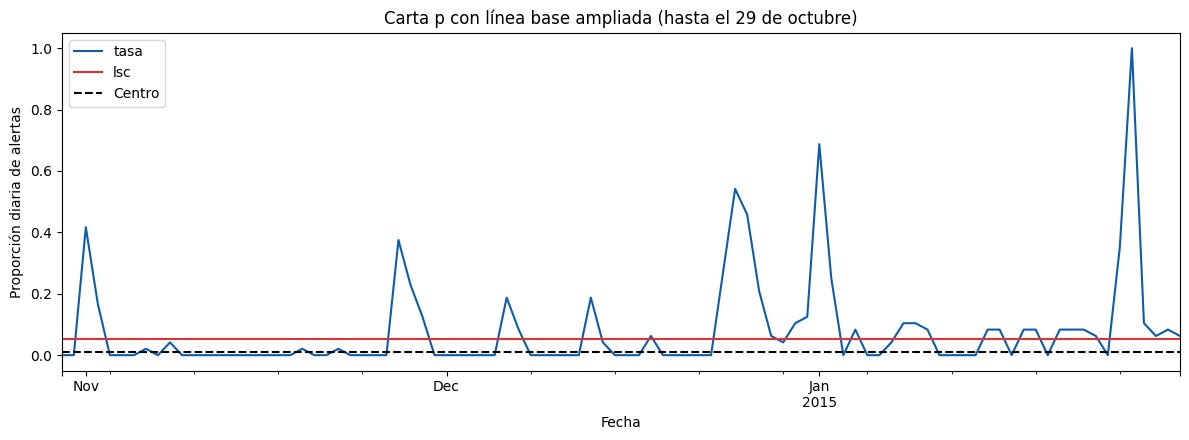

In [17]:
# Carta p con la línea base ampliada (solo el seguimiento nuevo)
f = pd.DataFrame({"valor": df.value, "media_3h": df.value.rolling(6).mean(),
                  "desv_3h": df.value.rolling(6).std(), "cambio_3h": df.value.diff(6)}).dropna()
C2 = pd.Timestamp("2014-10-30")
b2 = f.index < C2
f["ranura"] = ranura(f.index)
f["resid"] = f.valor - f.ranura.map(f.loc[b2].groupby("ranura").valor.median())
f["resid_3h"] = f.resid.rolling(6).mean()
f = f.dropna(); b2 = f.index < C2
m2 = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1).fit(f.loc[b2, VARIABLES])
f["score"] = -m2.score_samples(f[VARIABLES])
f["alerta"] = f.score >= f.loc[b2, "score"].quantile(0.99)
d2 = f.groupby(f.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
p2 = f.loc[b2, "alerta"].mean()
d2["tasa"] = d2.alertas / d2.lecturas
d2["lsc"] = p2 + 3 * np.sqrt(p2 * (1 - p2) / d2.lecturas)
ax = d2.loc[C2:, ["tasa", "lsc"]].plot(figsize=(12, 4.5), color=["#0B5CAD", "#D33"])
ax.axhline(p2, color="black", ls="--", label="Centro")
ax.set(ylabel="Proporción diaria de alertas", xlabel="Fecha", title="Carta p con línea base ampliada (hasta el 29 de octubre)")
ax.legend(); plt.tight_layout(); plt.show()

**Respuesta:**

Se repitió el procedimiento completo (perfil, modelo, umbral y carta p) con la línea base del 1 de julio al 29 de octubre y, como contraste, con una línea base contaminada hasta el 30 de noviembre:

| Versión | Lecturas base | Lecturas seguimiento | Umbral p99 | Alertas base | Alertas seguimiento | Episodios | En ventana | Días fuera |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Original (hasta 15-oct) | 5,125 | 5,184 | 0.5918 | 52 | 347 | 55 | 23 | 34 |
| Ampliada (hasta 29-oct) | 5,797 | 4,512 | 0.5891 | 58 | 358 | 53 | 22 | 36 |
| Contaminada (hasta 30-nov) | 7,333 | 2,976 | 0.5852 | 74 | 170 | 24 | 13 | 11 |

**Línea base ampliada.** Agregar dos semanas limpias casi no cambia el modelo: el umbral baja de 0.5918 a 0.5891 y p̄ pasa de 0.01015 a 0.01001. Las señales principales se mantienen (1-2 de noviembre; 27-29 de noviembre; 24-27 y 30-31 de diciembre; 1-2 de enero; 26-29 de enero). Los días fuera de control suben de 34 a 36: aparecen el 18 y 28 de diciembre, el 4 y el 24 de enero (tres de ellos, el 28 de diciembre, el 4 y el 24 de enero, pegados a ventanas) y salen el 22 de noviembre y el 14 de diciembre, que eran días límite con 3 o 4 alertas. Desde el 1 de diciembre, que ambas versiones evalúan, son 28 días fuera con la original y 31 con la ampliada.

**Línea base contaminada.** Al incluir las ventanas 1 y 2 en la línea base, el modelo aprende esos eventos como "normales": con la misma regla de percentil, los días fuera de control desde el 1 de diciembre caen de 28 a 11 y los episodios en ventana de 15 a 13. La ampliación solo es segura si la línea base nueva no contiene eventos que se quieren detectar. Como siempre, estas variaciones son diferencias estadísticas del detector y no cambios en la cantidad de eventos reales.

### Pregunta 3.2
Compare el modelo con las cinco variables (con perfil semanal) frente a un modelo con cuatro variables sin perfil y un modelo que usa solo la lectura (valor): alertas, episodios y coincidencia con las ventanas.

In [18]:
sin_perfil = ["valor", "media_3h", "desv_3h", "cambio_3h"]
modelos = {"5 variables (con perfil)": VARIABLES, "4 variables (sin perfil)": sin_perfil, "Solo valor": ["valor"]}
filas = []
for nombre, cols in modelos.items():
    r = ejecutar(CORTE, cols)
    e = r["ep"]
    filas.append({"Modelo": nombre, "Umbral p99": r["umbral"], "Alertas seguimiento": r["alertas_seg"],
                  "Episodios": r["episodios"], "Episodios en ventana": r["en_ventana"],
                  "% episodios en ventana": round(100 * r["en_ventana"] / max(r["episodios"], 1), 1),
                  "Ventanas cubiertas": sum(bool(((e.inicio <= b) & (e.fin >= a)).any()) for a, b in ventanas),
                  "Días fuera de control": r["dias_fuera"]})
comparacion = pd.DataFrame(filas)
display(comparacion)

,Modelo,Umbral p99,Alertas seguimiento,Episodios,Episodios en ventana,% episodios en ventana,Ventanas cubiertas,Días fuera de control
0,5 variables (con perfil),0.5918,347,55,23,41.8,5,34
1,4 variables (sin perfil),0.5684,173,73,15,20.5,4,21
2,Solo valor,0.5699,193,88,18,20.5,5,33


**Respuesta:**

Se compararon tres modelos con la misma línea base (1 de julio al 15 de octubre), el mismo seguimiento y el percentil 99 como umbral:

| Modelo | Umbral p99 | Alertas | Episodios | Episodios en ventana | % en ventana | Ventanas cubiertas | Días fuera |
|---|---:|---:|---:|---:|---:|---:|---:|
| 5 variables (con perfil semanal) | 0.5918 | 347 | 55 | 23 | 41.8 % | 5 de 5 | 34 |
| 4 variables (sin perfil) | 0.5684 | 173 | 73 | 15 | 20.5 % | 4 de 5 | 21 |
| Solo valor | 0.5699 | 193 | 88 | 18 | 20.5 % | 5 de 5 | 33 |

El modelo con perfil semanal produce menos episodios que el de solo valor (55 frente a 88) pero con mayor coincidencia: 23 episodios en ventana (41.8 %) frente a 18 y 15 (20.5 % en ambos). Tiene más alertas porque los eventos reales duran más (episodios de 12 a 20 horas), no porque dispare más veces. Los modelos sin perfil confunden el ciclo diario normal con anomalías: el de solo valor tiene 135 alertas fuera de ventanas concentradas en los valles y picos diarios (40 entre las 03:00 y las 04:59, 26 a las 19:00 y 37 entre las 22:00 y las 23:59), con un desvío medio de apenas unos 2,000 pasajeros frente al perfil, y el de 4 variables deja una ventana sin cubrir. Elegiría el modelo de 5 variables, porque medir la distancia a lo esperado según día y hora separa lo habitual de lo extraño. Su costo es una dependencia: el perfil solo es válido mientras la línea base represente la demanda normal, y la de julio a octubre no incluye invierno.

### Pregunta 3.3
Redacte una recomendación ejecutiva de ocho líneas con cifras, responsable, acción, límite y condición de revisión.

**Respuesta:**

1. Recomiendo implementar el modelo Isolation Forest de 5 variables (con perfil semanal) con umbral en el percentil 99.5 (0.6251), que en el seguimiento generó 220 alertas agrupadas en 36 episodios, de los cuales 23 coinciden con las ventanas de referencia y las 5 ventanas quedan cubiertas.
2. La jefatura de despacho es la responsable de operar la cola; un supervisor de turno revisa cada día el episodio de mayor puntuación.
3. Acción: confirmar cada episodio con evidencia externa (calendario y cambio de hora, clima, bitácora de ingesta) antes de reasignar vehículos o declarar un evento.
4. Límite operativo: 1 episodio revisado por día; con esa capacidad se atienden 27 episodios y quedan 9 en cola (8 de ellos dentro de ventanas, es decir, en días de evento), que requieren refuerzo del equipo.
5. Se vigila la carta p diaria con límite superior de 0.0535 (3 o más alertas en un día) como señal para investigar, no como prueba de falla: en la línea base 6 de 107 días también superaron el límite.
6. Se descarta el percentil 98 (94 episodios, 30 en cola y solo 23.4 % en ventana) y el modelo de solo valor (20.5 % de episodios en ventana).
7. Condición de revisión: recalibrar perfil, umbral y límites cuando se acumule una línea base con invierno y primavera (idealmente un año completo), si la cola supera los 9 episodios o si aparece un evento confirmado que no fue alertado.
8. Nunca ampliar la línea base con periodos que contengan eventos que se quieren detectar: al incluir dos ventanas, los días fuera de control posteriores cayeron de 28 a 11.

## Entrega
Suba el notebook ejecutado a su GitHub personal en `semana12/` y comparta también el enlace a su Colab. Incluya las diez respuestas individuales y un cierre que distinga **alerta estadística** (el modelo señala algo inusual), **investigación** (alguien verifica con evidencia externa) y **evento operativo demostrado** (la causa queda confirmada). El cuestionario individual de la semana se rinde aparte.

**Cierre:**

Una **alerta estadística** es lo que produce el modelo: por ejemplo, el 2 de noviembre a la 01:00 hubo 39,197 pasajeros frente a unos 22,800 esperados y la puntuación fue la más alta del seguimiento (0.759). Una **investigación** comienza cuando alguien contrasta esa alerta con evidencia externa, como el calendario, el cambio de hora, el clima o la bitácora de ingesta. Un **evento operativo demostrado** existe solo cuando esa evidencia confirma la causa; hasta entonces, incluso las lecturas más extremas (como las 12 de la madrugada del 27 de enero con valores entre 8 y 80 pasajeros) son hipótesis. En este laboratorio la coincidencia con las ventanas de NAB respalda la utilidad del detector, pero no convierte ninguna alerta en una causa.